# Steam: SQL-анализ ценовых сегментов

**Цель:** сравнить ценовые сегменты Steam по количеству игр и отзывов.

**Вопросы:**
1. В каком ценовом сегменте больше всего игр?
2. В каких сегментах в среднем больше положительных и отрицательных отзывов?

Это продолжение `1_EDA.ipynb`. Используем уже подготовленную базу `steam_market.db`. Количество отзывов - не количество игроков и не продажи.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ищем базу рядом с ноутбуком или в папке data проекта
possible_paths = [
    Path("steam_market.db"),
    Path("../data/steam_market.db"),
    Path("data/steam_market.db"),
]
db_path = next((p for p in possible_paths if p.exists()), None)
if db_path is None:
    raise FileNotFoundError("Не найдена steam_market.db. Положи базу рядом с ноутбуком или в папку data.")

conn = sqlite3.connect(db_path)
print("База:", db_path)
print("Количество игр:", pd.read_sql_query("SELECT COUNT(*) AS n FROM games", conn).iloc[0, 0])

База: steam_market.db
Количество игр: 27075


## 1. Сравнение ценовых сегментов

Разделим игры на четыре группы: бесплатные, до $5, от $5 до $15 и дороже $15. Для каждой группы посчитаем количество игр, долю от всех игр в датасете, среднюю цену и среднее количество отзывов.

In [2]:
query = """
WITH PriceSegmentedGames AS (
    SELECT
        name,
        price,
        positive_ratings,
        negative_ratings,
        CASE
            WHEN price = 0 THEN '1. Free (Бесплатные)'
            WHEN price > 0 AND price <= 5 THEN '2. Budget (До $5)'
            WHEN price > 5 AND price <= 15 THEN '3. Mid-core ($5-$15)'
            ELSE '4. Premium (Более $15)'
        END AS price_segment
    FROM games
),
SegmentAggregates AS (
    SELECT
        price_segment,
        COUNT(*) AS total_games,
        ROUND(AVG(price), 2) AS avg_price,
        ROUND(AVG(positive_ratings), 0) AS avg_positive_ratings,
        ROUND(AVG(negative_ratings), 0) AS avg_negative_ratings
    FROM PriceSegmentedGames
    GROUP BY price_segment
)
SELECT
    price_segment,
    total_games,
    ROUND(CAST(total_games AS REAL) / SUM(total_games) OVER() * 100, 2) AS games_share_percent,
    avg_price,
    avg_positive_ratings,
    avg_negative_ratings
FROM SegmentAggregates
ORDER BY price_segment;
"""

pricing_mart = pd.read_sql_query(query, conn)
display(pricing_mart)

,price_segment,total_games,games_share_percent,avg_price,avg_positive_ratings,avg_negative_ratings
0,1. Free (Бесплатные),2560,9.46,0.00,3065.0,630.0
1,2. Budget (До $5),13293,49.10,2.63,144.0,35.0
2,3. Mid-core ($5-$15),9246,34.15,8.78,1042.0,144.0
3,4. Premium (Более $15),1976,7.30,24.49,3898.0,1167.0


**Как читать таблицу:** `games_share_percent` — доля игр в нашем датасете, а не доля рынка по продажам или выручке.

## 2. Визуализация результатов SQL

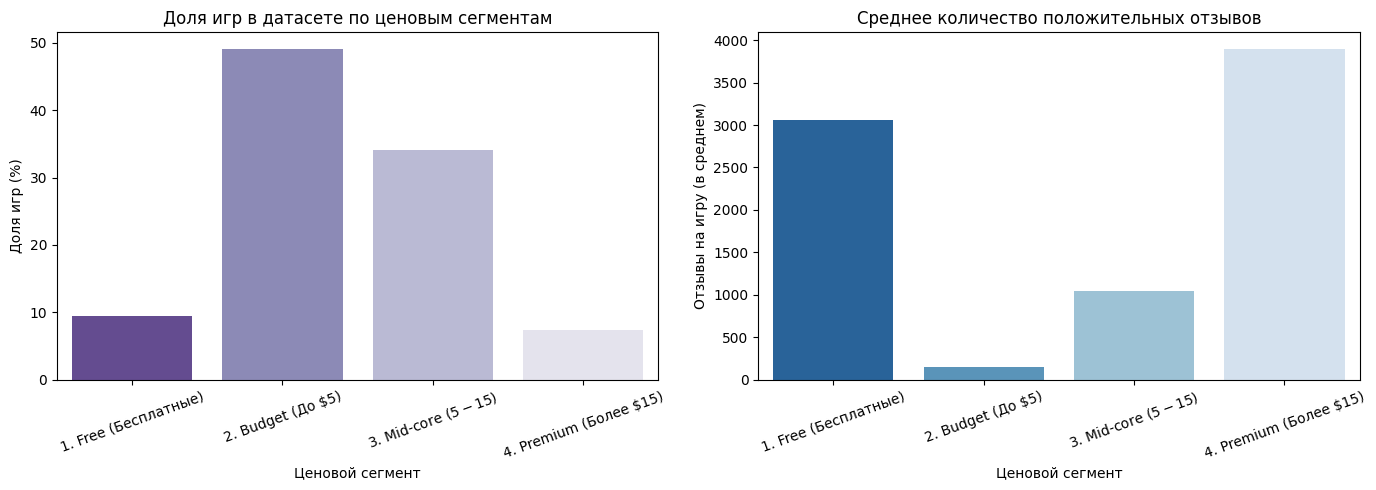

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=pricing_mart, x='price_segment', y='games_share_percent',
            hue='price_segment', palette='Purples_r', legend=False, ax=axes[0])
axes[0].set_title('Доля игр в датасете по ценовым сегментам')
axes[0].set_xlabel('Ценовой сегмент')
axes[0].set_ylabel('Доля игр (%)')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=pricing_mart, x='price_segment', y='avg_positive_ratings',
            hue='price_segment', palette='Blues_r', legend=False, ax=axes[1])
axes[1].set_title('Среднее количество положительных отзывов')
axes[1].set_xlabel('Ценовой сегмент')
axes[1].set_ylabel('Отзывы на игру (в среднем)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## 3. Положительные и отрицательные отзывы

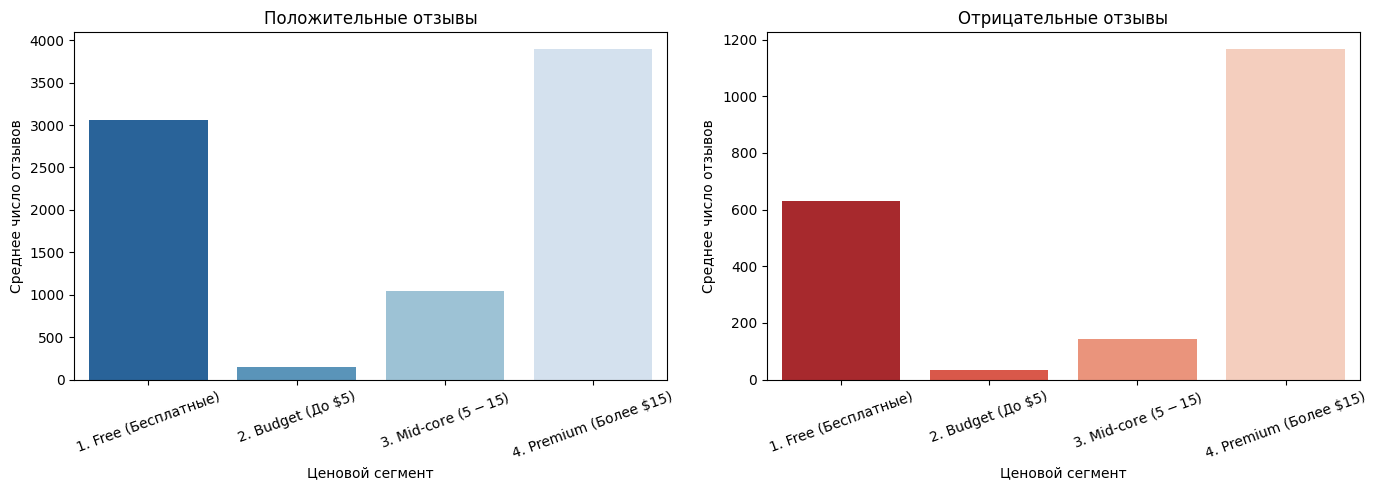

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=pricing_mart, x='price_segment', y='avg_positive_ratings',
            hue='price_segment', palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Положительные отзывы')
axes[0].set_xlabel('Ценовой сегмент')
axes[0].set_ylabel('Среднее число отзывов')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=pricing_mart, x='price_segment', y='avg_negative_ratings',
            hue='price_segment', palette='Reds_r', legend=False, ax=axes[1])
axes[1].set_title('Отрицательные отзывы')
axes[1].set_xlabel('Ценовой сегмент')
axes[1].set_ylabel('Среднее число отзывов')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## 4. Вывод

- Самый многочисленный ценовой сегмент — игры стоимостью до $5: 13 293 игры (49,10% выборки). Наибольшее среднее количество положительных отзывов наблюдается в сегменте дороже $15 — 3 898 на игру. При этом количество отзывов не равно числу игроков или продаж.
- Среднее количество отзывов отличается между сегментами, но **по числу отзывов нельзя напрямую судить о числе игроков или качестве игры**.
- Для сравнения пользовательских оценок лучше использовать **долю положительных отзывов**, как в первом ноутбуке.

**Практический итог:** при изучении рынка Steam полезно учитывать одновременно цену, количество отзывов и долю положительных оценок. Эти результаты описывают связи в данных, но не доказывают влияние цены на популярность.

**Использованные инструменты:** SQLite, `WITH` (CTE), `CASE WHEN`, `GROUP BY`, оконная функция `SUM() OVER()`, Pandas, Seaborn.

In [5]:
conn.close()